# 🌐 Tema 6.3: Grafos Multiplex (Múltiples Relaciones)
Ejemplo didáctico: La Vida Universitaria.

### 1. El Problema del Grafo Simple (`nx.Graph`)
Intentemos modelar a dos estudiantes (Ana y Beto) que son compañeros de proyecto, pero que también juegan Valorant juntos en las noches.

In [2]:
import json
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. Abrir el JSON
with open('./trollfarm.json', encoding='utf-8') as f:
    datos = json.load(f)
print("Cuentas en el JSON:", len(datos))   # 23

# 2. Recorrer cada cuenta y separar lo social de los metadatos
filas_retweets = []
filas_metadata = []

for usuario in datos:
    origen = usuario['account_id'].strip().upper()      

    actividad = usuario.get('activity') or {}            
    for destino in actividad.get('retweets') or []:
        filas_retweets.append({'Origen': origen,
                               'Destino': destino.strip().upper(),
                               'Relacion': 'Retweet'})

    meta = usuario.get('metadata') or {}
    filas_metadata.append({'account_id': origen,
                           'last_ip': meta.get('last_ip'),
                           'payment_hash': meta.get('payment_hash')})

Cuentas en el JSON: 23


In [3]:
df_retweets = pd.DataFrame(filas_retweets)
print("Retweets crudos:", len(df_retweets))   # 49

auto = (df_retweets['Origen'] == df_retweets['Destino']).sum()
df_retweets = df_retweets[df_retweets['Origen'] != df_retweets['Destino']]
df_retweets = df_retweets.drop_duplicates()
print("Auto-retweets eliminados:", auto)      # 12
print("Retweets válidos:", len(df_retweets))  # 37

Retweets crudos: 49
Auto-retweets eliminados: 12
Retweets válidos: 37


In [4]:
df_meta = pd.DataFrame(filas_metadata).drop_duplicates(subset='account_id')   # TROLL_BOT_1 venía 2 veces

def conectar_por(columna, nombre_relacion):
    # dropna es CLAVE: sin él, todos los usuarios con tarjeta null quedarían "conectados" entre sí
    base = df_meta.dropna(subset=[columna])
    pares = base.merge(base, on=columna, suffixes=('_A', '_B'))
    pares = pares[pares['account_id_A'] < pares['account_id_B']]   # sin self-pairs ni espejos
    return pd.DataFrame({'Origen': pares['account_id_A'],
                         'Destino': pares['account_id_B'],
                         'Relacion': nombre_relacion})

df_tarjeta = conectar_por('payment_hash', 'Misma_Tarjeta')
df_ip      = conectar_por('last_ip', 'Misma_IP')

# Tabla maestra con las 3 capas
tabla_maestra = pd.concat([df_retweets, df_tarjeta, df_ip], ignore_index=True)
print(tabla_maestra['Relacion'].value_counts())   # Retweet 37 | Misma_Tarjeta 15 | Misma_IP 15
display(tabla_maestra.head(10))

Relacion
Retweet          37
Misma_Tarjeta    15
Misma_IP         15
Name: count, dtype: int64


,Origen,Destino,Relacion
0,TROLL_BOT_1,REAL_USER_11,Retweet
1,REAL_USER_14,REAL_USER_15,Retweet
2,REAL_USER_14,REAL_USER_11,Retweet
3,REAL_USER_13,REAL_USER_3,Retweet
4,REAL_USER_13,REAL_USER_9,Retweet
5,TROLL_BOT_5,REAL_USER_12,Retweet
6,TROLL_BOT_5,TROLL_BOT_1,Retweet
7,REAL_USER_12,REAL_USER_15,Retweet
8,REAL_USER_11,REAL_USER_14,Retweet
9,REAL_USER_11,REAL_USER_6,Retweet


### 2. La Solución: MultiGraph (El Grafo Multicapa)
Para modelar la complejidad humana, usamos `nx.MultiGraph`, que permite múltiples aristas paralelas entre los mismos dos nodos.

In [5]:
MG = nx.from_pandas_edgelist(tabla_maestra, source='Origen', target='Destino',
                             edge_attr='Relacion', create_using=nx.MultiDiGraph())

print("Nodos totales:", MG.number_of_nodes())    # 21
print("Aristas totales:", MG.number_of_edges())  # 67

Nodos totales: 21
Aristas totales: 67


### 3. Diseccionando el Grafo (Slicing)
Si queremos saber quién es el mejor jugando Valorant, la relación de 'Roomies' o 'Proyecto' solo nos hace ruido. Debemos extraer (rebanar) esa capa específica.

In [8]:
# 1. Rebanar solo la capa financiera
aristas_tarjeta = [(u, v) for u, v, d in MG.edges(data=True) if d['Relacion'] == 'Misma_Tarjeta']

# 2. Grafo simple no dirigido
G_tarjeta = nx.Graph()
G_tarjeta.add_edges_from(aristas_tarjeta)

# 3. Componentes conectados = grupos que comparten tarjeta
tribus = list(nx.connected_components(G_tarjeta))
print("Grupos encontrados:", len(tribus))   # 1

anillo_fraude = sorted(max(tribus, key=len))
print("Anillo de fraude:", anillo_fraude)

tarjeta = df_meta[df_meta['account_id'].isin(anillo_fraude)]['payment_hash'].unique()
print("Tarjeta comprometida:", tarjeta)
display(df_meta[df_meta['account_id'].isin(anillo_fraude)])

Grupos encontrados: 1
Anillo de fraude: ['TROLL_BOT_1', 'TROLL_BOT_2', 'TROLL_BOT_3', 'TROLL_BOT_4', 'TROLL_BOT_5', 'TROLL_BOT_6']
Tarjeta comprometida: <StringArray>
['VISA-4455-XXXX-9090']
Length: 1, dtype: str


,account_id,last_ip,payment_hash
0,TROLL_BOT_1,104.28.19.112,VISA-4455-XXXX-9090
3,TROLL_BOT_5,104.28.19.112,VISA-4455-XXXX-9090
10,TROLL_BOT_4,104.28.19.112,VISA-4455-XXXX-9090
11,TROLL_BOT_6,104.28.19.112,VISA-4455-XXXX-9090
16,TROLL_BOT_3,104.28.19.112,VISA-4455-XXXX-9090
22,TROLL_BOT_2,104.28.19.112,VISA-4455-XXXX-9090


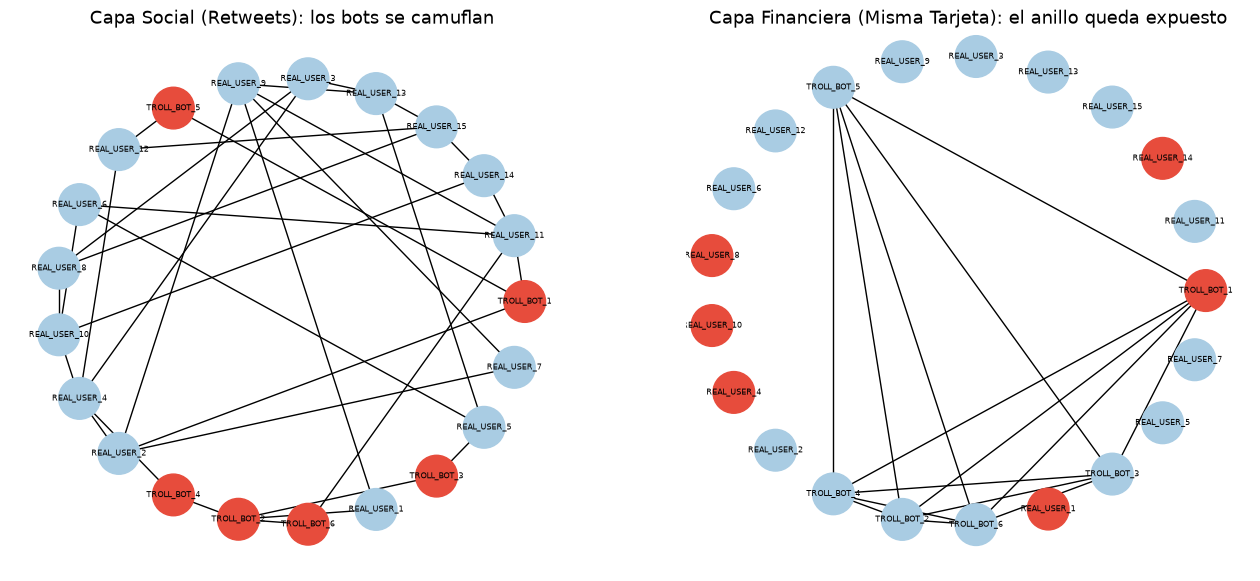

In [7]:
aristas_rt = [(u, v) for u, v, d in MG.edges(data=True) if d['Relacion'] == 'Retweet']
G_social = nx.Graph()
G_social.add_nodes_from(MG.nodes())
G_social.add_edges_from(aristas_rt)

G_tarjeta.add_nodes_from(MG.nodes())   # todos los nodos en ambas capas
pos_fija = nx.circular_layout(MG)
colores = ['#E74C3C' if n in anillo_fraude else '#A9CCE3' for n in MG.nodes()]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
nx.draw(G_social, pos_fija, ax=axes[0], with_labels=True, node_color=colores, node_size=900, font_size=6)
axes[0].set_title('Capa Social (Retweets): los bots se camuflan', fontsize=13)
nx.draw(G_tarjeta, pos_fija, ax=axes[1], with_labels=True, node_color=colores, node_size=900, font_size=6)
axes[1].set_title('Capa Financiera (Misma Tarjeta): el anillo queda expuesto', fontsize=13)
plt.show()

## 🚨 El Veredicto

**1. ¿Quiénes son los bots del anillo de fraude?**
Son **6 cuentas**: `TROLL_BOT_1`, `TROLL_BOT_2`, `TROLL_BOT_3`, `TROLL_BOT_4`, `TROLL_BOT_5` y `TROLL_BOT_6`. La cuenta `troll_bot_1` (en minúsculas) es un duplicado de `TROLL_BOT_1` y también debe banearse.

En la capa de Retweets se camuflan: les dan RT a usuarios reales (real_user_11, real_user_12, etc.). Pero en la capa financiera forman un solo componente conectado. Además, los 6 comparten la misma IP (`104.28.19.112`), lo que confirma que los opera una sola persona o servidor.

**2. ¿Qué tarjeta se debe bloquear?**
`VISA-4455-XXXX-9090`

**3. ¿Cómo pasarle este descubrimiento a un modelo tabular?**
Convirtiendo la información del grafo en **columnas nuevas de la matriz X** (feature engineering de grafos), una fila por usuario:
- `cuentas_misma_tarjeta`: con cuántas cuentas comparte tarjeta (grado en la capa financiera). Un usuario normal tiene 0; un bot, 5.
- `cuentas_misma_ip`: lo mismo, pero en la capa de infraestructura.
- `tamano_componente`: tamaño del grupo conectado al que pertenece.
- `en_anillo` (0/1): si pertenece a un componente de más de N cuentas.

No conviene meter el hash de la tarjeta directo como One-Hot: tiene demasiados valores únicos y, si los estafadores usan una tarjeta nueva, el modelo no la reconocería. Lo que se aprende es el **patrón**: "muchas cuentas comparten la misma tarjeta o IP". Ese patrón sí generaliza a la siguiente granja de bots.
